<center><h1>Last_First_HW4</h1></center>
<br>
<br>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc, roc_auc_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler
import warnings

### (b) Splitting Data

In [2]:
data_dir=os.path.join('..', 'Data', 'AReM')
folders=['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']

train_files=[]
test_files=[]

for folder in folders:
    folder_path=os.path.join(data_dir, folder)
    if not os.path.exists(folder_path):
        continue
    for file in sorted(os.listdir(folder_path)):
        if not file.endswith('.csv'):
            continue
        file_path=os.path.join(folder_path, file)
        if folder in ['bending1', 'bending2']:
            if file in ['dataset1.csv', 'dataset2.csv']:
                test_files.append((folder, file_path))
            else:
                train_files.append((folder, file_path))
        else:
            if file in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                test_files.append((folder, file_path))
            else:
                train_files.append((folder, file_path))

print(f"Training instances: {len(train_files)}")
print(f"Testing instances: {len(test_files)}")

Training instances: 69
Testing instances: 19


### (c) Feature Extraction

Mean, Median, Standard Deviation, Variance, Range, Interquartile Range, Minimum, Maximum, Skewness, First Quartile, Third Quartile.

In [3]:
columns_of_interest=['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'vg_rss23', 'ar_rss23']
metrics=['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']

def extract_features(file_list):
    dataset_features=[]
    for folder, path in file_list:
        try:
            df=pd.read_csv(path, skiprows=4)
            if df.shape[1]==1:
                df=pd.read_csv(path, skiprows=4, sep=r'\s+')
            df=df.iloc[:, 1:7]
            df.columns=columns_of_interest
            df=df.apply(pd.to_numeric, errors='coerce').dropna()
            
            row_features=[]
            for col in columns_of_interest:
                row_features.extend([
                    df[col].min(),
                    df[col].max(),
                    df[col].mean(),
                    df[col].median(),
                    df[col].std(),
                    df[col].quantile(0.25),
                    df[col].quantile(0.75)
                ])
            row_features.append(folder)
            dataset_features.append(row_features)
        except Exception as e:
            print(f"Error {path}: {e}")

    feature_cols=[]
    for i in range(1, 7):
        for metric in metrics:
            feature_cols.append(f"{metric}_{i}")
    feature_cols.append("Activity")
    return pd.DataFrame(dataset_features, columns=feature_cols)

all_files=train_files+test_files
feature_df=extract_features(all_files)
feature_df.index=np.arange(1, len(feature_df)+1)
feature_df.index.name='Instance'
feature_df.head()

,min_1,max_1,mean_1,median_1,std_1,1st_quart_1,3rd_quart_1,min_2,max_2,mean_2,...,1st_quart_5,3rd_quart_5,min_6,max_6,mean_6,median_6,std_6,1st_quart_6,3rd_quart_6,Activity
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1
2,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1
3,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1
4,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1
5,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1


In [5]:
features_only=feature_df.drop(columns=['Activity'])
std_estimates=features_only.std()
n_bootstraps=1000
ci_lower=[]
ci_upper=[]

np.random.seed(42)
for col in features_only.columns:
    bootstrapped_stds=[]
    for _ in range(n_bootstraps):
        sample=features_only[col].sample(frac=1, replace=True)
        bootstrapped_stds.append(sample.std())
    ci_lower.append(np.percentile(bootstrapped_stds, 5))
    ci_upper.append(np.percentile(bootstrapped_stds, 95))

bootstrap_results=pd.DataFrame({
    'Estimated_Std': std_estimates.values,
    '90%_CI_Lower': ci_lower,
    '90%_CI_Upper': ci_upper
}, index=features_only.columns)

bootstrap_results

,Estimated_Std,90%_CI_Lower,90%_CI_Upper
min_1,9.624011,8.336430,10.784675
max_1,4.207745,3.119497,5.174200
mean_1,5.276431,4.600609,5.820921
median_1,5.386624,4.712754,5.995648
std_1,1.771282,1.560548,1.949806
1st_quart_1,6.127846,5.489005,6.590422
3rd_quart_1,5.031028,4.181576,5.666503
min_2,0.000000,0.000000,0.000000
max_2,5.059656,4.623330,5.394707
mean_2,1.577908,1.406770,1.705383


Mean, captures the baseline signal level .   
Minimum, reflects the lower physical bound of signal intensity.   
Maximum, highlights extreme spikes and acceleration impulses.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

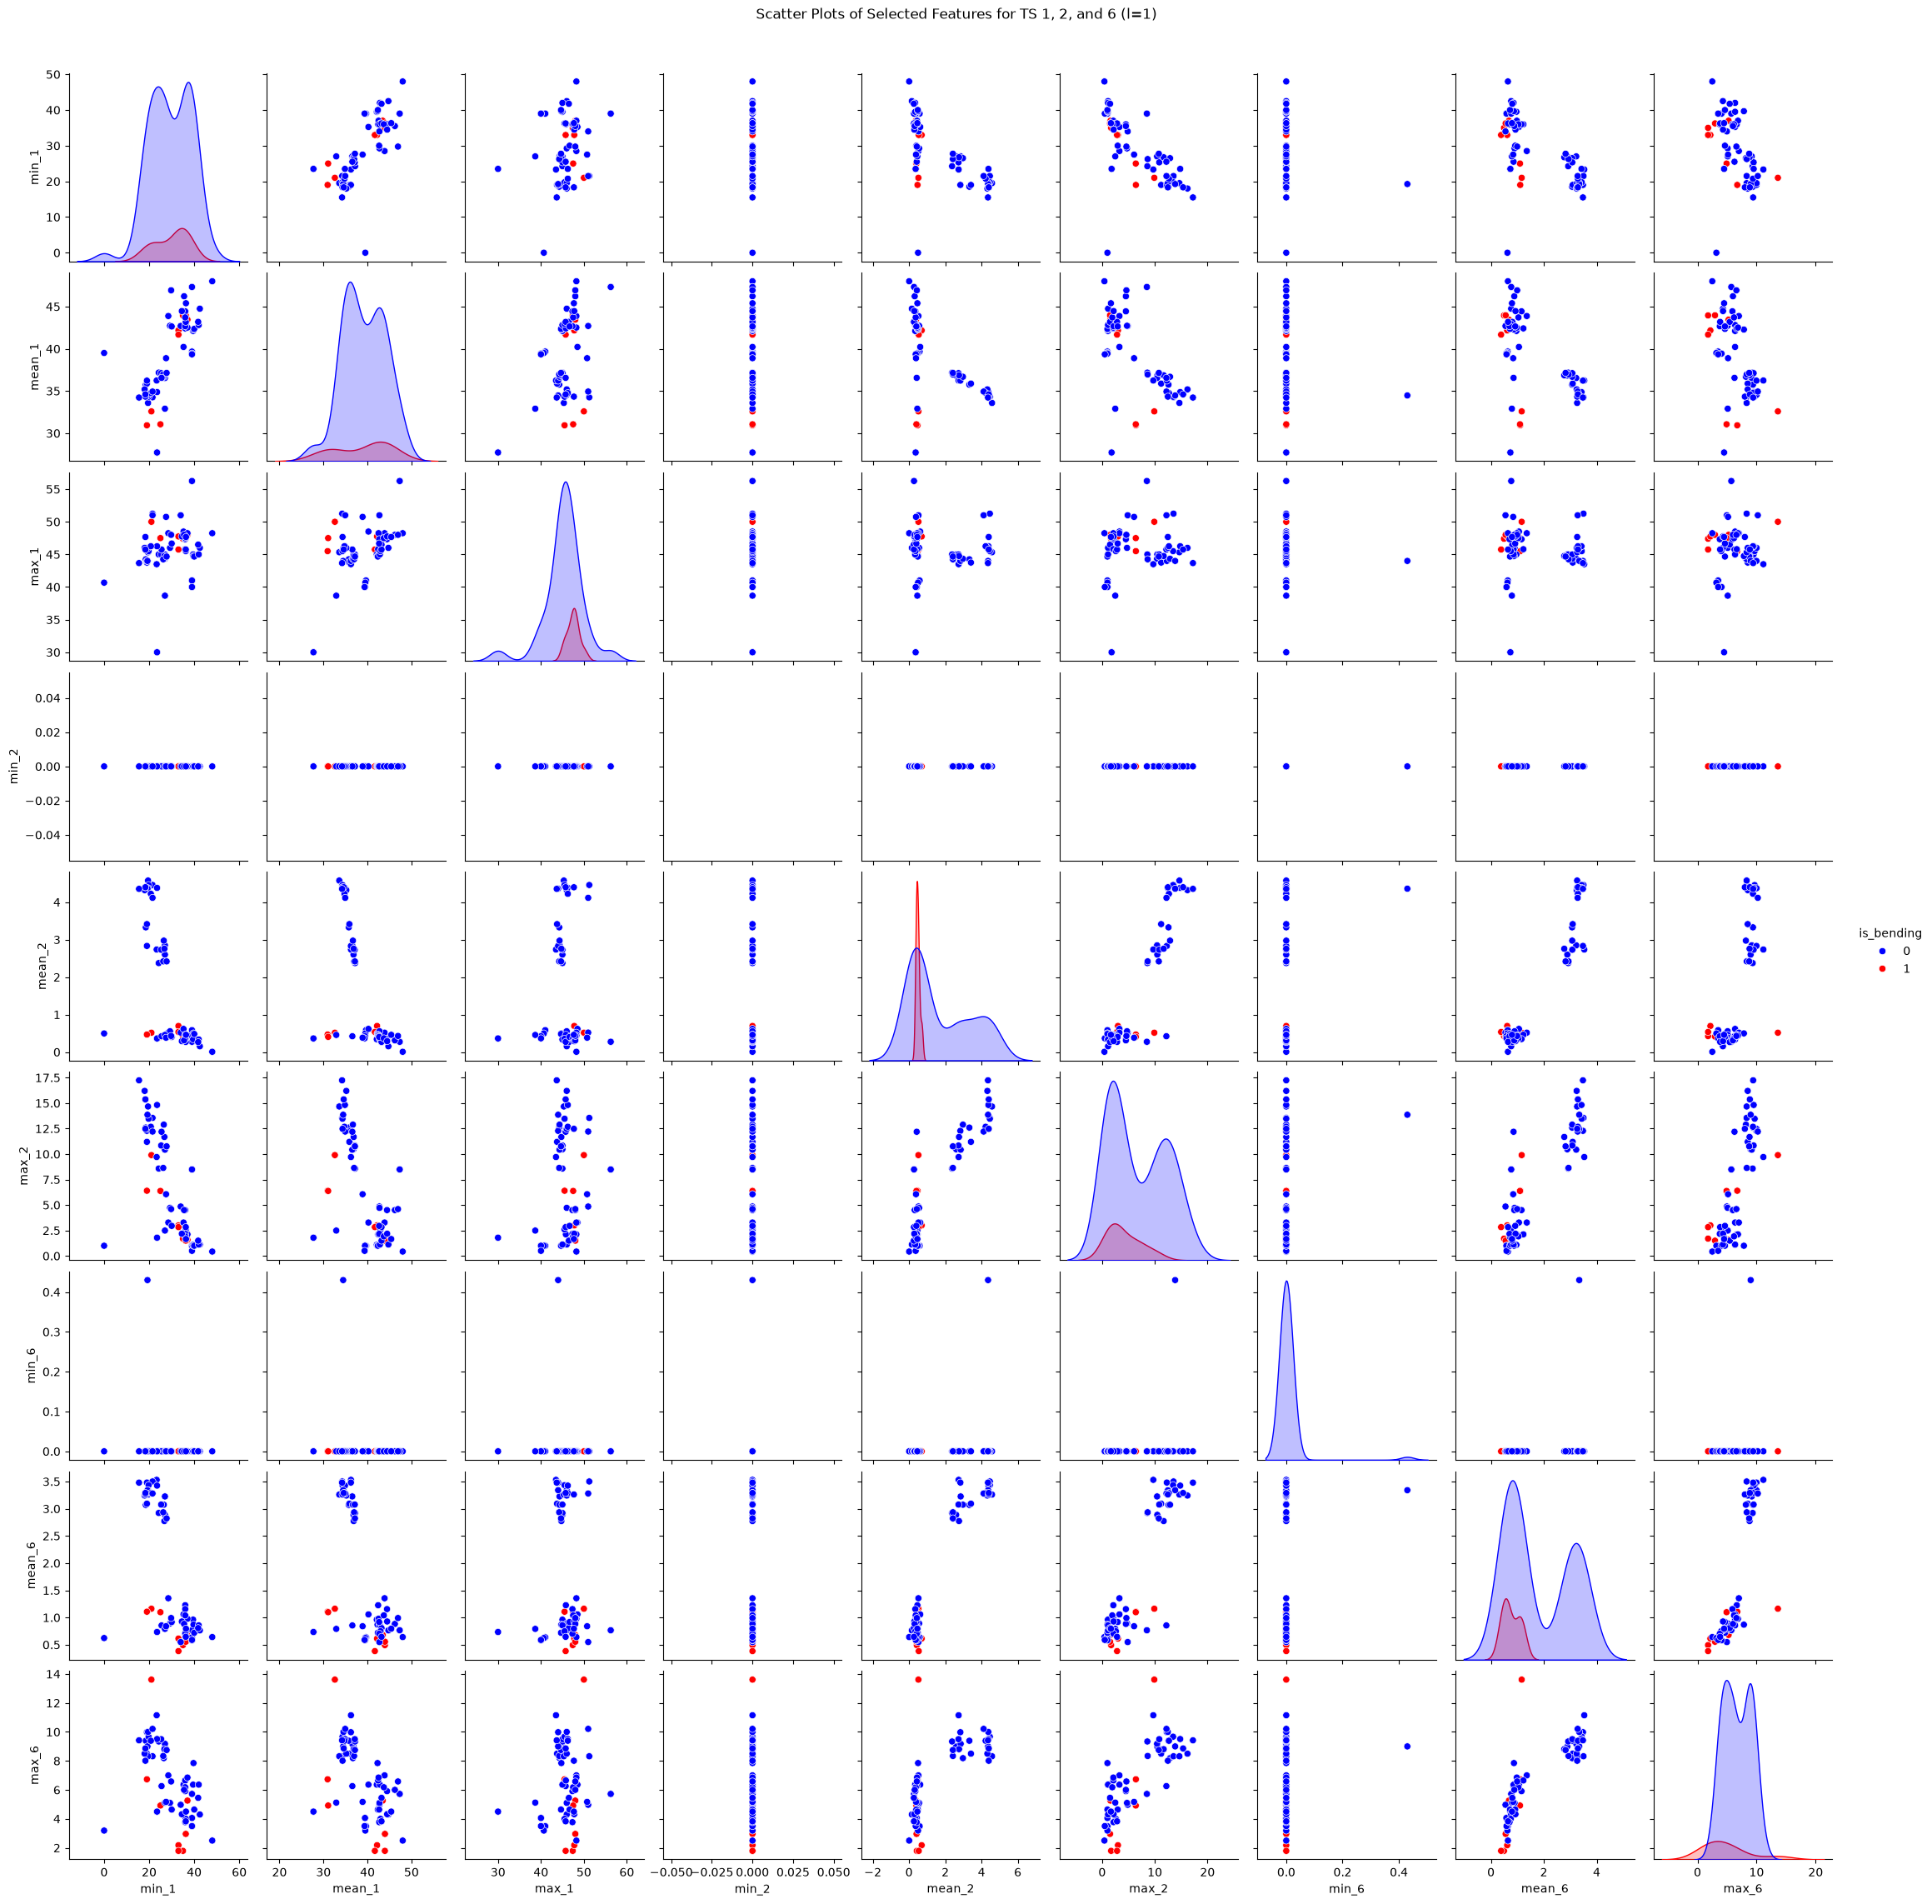

In [4]:
train_df=extract_features(train_files)
train_df['is_bending']=train_df['Activity'].apply(lambda x: 1 if 'bending' in x else 0)

selected_features=['min', 'mean', 'max']
selected_ts=[1, 2, 6]

feature_subset=[]
for ts in selected_ts:
    for feat in selected_features:
        feature_subset.append(f"{feat}_{ts}")

sns.pairplot(train_df[feature_subset+['is_bending']], hue='is_bending', palette={0: 'blue', 1: 'red'})
plt.suptitle('Scatter Plots of Selected Features for TS 1, 2, and 6 (l=1)', y=1.02)
plt.show()

#### ii. Splitted Plots

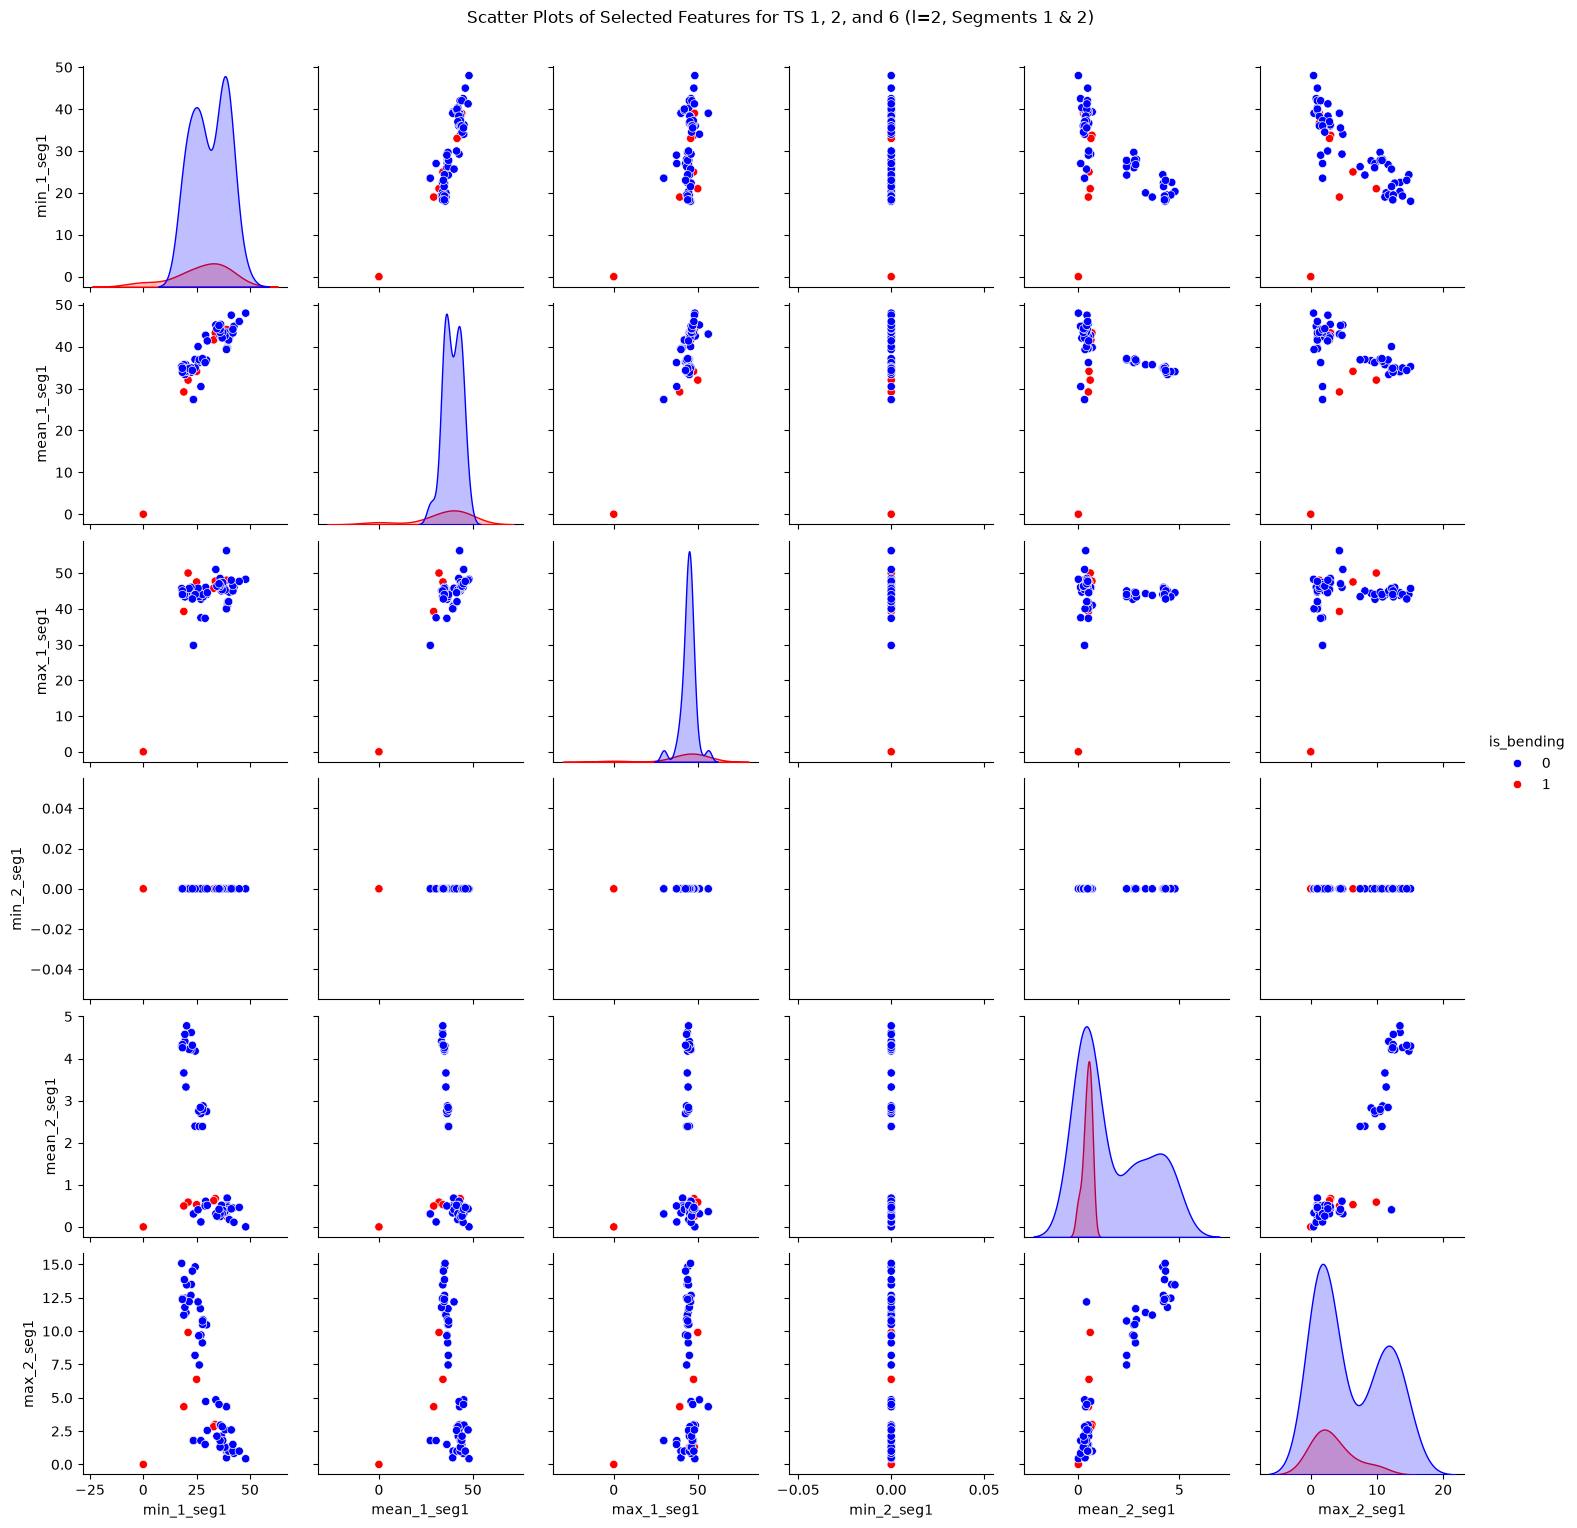

In [13]:
def extract_split_features(file_list, l=1):
    records=[]
    for folder, path in file_list:
        df=pd.read_csv(path, skiprows=4)
        if df.shape[1]==1:
            df=pd.read_csv(path, skiprows=4, sep=r'\s+')
        df=df.iloc[:, 1:7]
        df.columns=columns_of_interest
        df=df.apply(pd.to_numeric, errors='coerce').dropna()
        
        n_samples=len(df)
        split_size=int(np.floor(n_samples/l))
        
        instance_features=[]
        for segment_idx in range(l):
            sub_df=df.iloc[segment_idx*split_size:(segment_idx+1)*split_size]
            for col in columns_of_interest:
                series=sub_df[col]
                s_min=series.min() if len(series)>0 else 0.0
                s_max=series.max() if len(series)>0 else 0.0
                s_mean=series.mean() if len(series)>0 else 0.0
                s_med=series.median() if len(series)>0 else 0.0
                s_std=series.std() if len(series)>1 else 0.0
                s_q1=series.quantile(0.25) if len(series)>0 else 0.0
                s_q3=series.quantile(0.75) if len(series)>0 else 0.0
                vals=[s_min, s_max, s_mean, s_med, s_std, s_q1, s_q3]
                vals=[0.0 if np.isnan(v) or np.isinf(v) else float(v) for v in vals]
                instance_features.extend(vals)
                
        instance_features.append(folder)
        records.append(instance_features)
        
    cols=[]
    for segment_idx in range(1, l+1):
        for ts_idx in range(1, 7):
            for m in metrics:
                cols.append(f"{m}_{ts_idx}_seg{segment_idx}")
    cols.append('Activity')
    
    res_df=pd.DataFrame(records, columns=cols)
    numeric_cols=[c for c in res_df.columns if c!='Activity']
    res_df[numeric_cols]=res_df[numeric_cols].fillna(0.0)
    return res_df

train_df_l2=extract_split_features(train_files, l=2)
train_df_l2['is_bending']=train_df_l2['Activity'].apply(lambda x: 1 if 'bending' in x else 0)

selected_cols_l2=[]
for seg in [1, 2]:
    for ts in [1, 2, 6]:
        for feat in ['min', 'mean', 'max']:
            selected_cols_l2.append(f"{feat}_{ts}_seg{seg}")

sns.pairplot(train_df_l2[selected_cols_l2[:6]+['is_bending']], hue='is_bending', palette={0: 'blue', 1: 'red'})
plt.suptitle('Scatter Plots of Selected Features for TS 1, 2, and 6 (l=2, Segments 1 & 2)', y=1.02)
plt.show()

Splitting into two sub-series generates features over shorter time horizons.

#### iii. Time Series Segments

In [12]:
raw_train_cache=[]
for folder, path in train_files:
    df=pd.read_csv(path, skiprows=4)
    if df.shape[1]==1:
        df=pd.read_csv(path, skiprows=4, sep=r'\s+')
    df=df.iloc[:, 1:7]
    df.columns=columns_of_interest
    df=df.apply(pd.to_numeric, errors='coerce').dropna()
    raw_train_cache.append((folder, df))

def fast_split_features(cached_data, l=1):
    records=[]
    for folder, df in cached_data:
        n_samples=len(df)
        split_size=int(np.floor(n_samples/l))
        instance_features=[]
        for segment_idx in range(l):
            sub_df=df.iloc[segment_idx*split_size:(segment_idx+1)*split_size]
            for col in columns_of_interest:
                series=sub_df[col]
                s_min=series.min() if len(series)>0 else 0.0
                s_max=series.max() if len(series)>0 else 0.0
                s_mean=series.mean() if len(series)>0 else 0.0
                s_med=series.median() if len(series)>0 else 0.0
                s_std=series.std() if len(series)>1 else 0.0
                s_q1=series.quantile(0.25) if len(series)>0 else 0.0
                s_q3=series.quantile(0.75) if len(series)>0 else 0.0
                vals=[0.0 if np.isnan(v) or np.isinf(v) else float(v) for v in [s_min, s_max, s_mean, s_med, s_std, s_q1, s_q3]]
                instance_features.extend(vals)
        instance_features.append(folder)
        records.append(instance_features)
    
    cols=[]
    for segment_idx in range(1, l+1):
        for ts_idx in range(1, 7):
            for m in metrics:
                cols.append(f"{m}_{ts_idx}_seg{segment_idx}")
    cols.append('Activity')
    res_df=pd.DataFrame(records, columns=cols)
    numeric_cols=[c for c in res_df.columns if c!='Activity']
    res_df[numeric_cols]=res_df[numeric_cols].fillna(0.0)
    return res_df

cv_records=[]
skf=StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for l in range(1, 21):
    train_l=fast_split_features(raw_train_cache, l=l)
    X_l=train_l.drop(columns=['Activity']).values
    y_l=train_l['Activity'].apply(lambda x: 1 if 'bending' in x else 0).values
    total_feats=X_l.shape[1]
    p_max=min(total_feats, 20)

    for train_idx, val_idx in skf.split(X_l, y_l):
        X_tr, X_val=X_l[train_idx], X_l[val_idx]
        y_tr, y_val=y_l[train_idx], y_l[val_idx]
        scaler=StandardScaler()
        X_tr_sc=np.nan_to_num(scaler.fit_transform(X_tr), nan=0.0)
        X_val_sc=np.nan_to_num(scaler.transform(X_val), nan=0.0)
        base_model=LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000, random_state=42)
        rfe=RFE(estimator=base_model, n_features_to_select=1, step=0.1 if total_feats>100 else 1)
        rfe.fit(X_tr_sc, y_tr)

        for p in range(1, p_max+1):
            selected=(rfe.ranking_<=p)
            clf=LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000, random_state=42)
            clf.fit(X_tr_sc[:, selected], y_tr)
            preds=clf.predict(X_val_sc[:, selected])
            score=accuracy_score(y_val, preds)
            cv_records.append({'l': l, 'p': p, 'score': score})

cv_df=pd.DataFrame(cv_records)
summary=cv_df.groupby(['l', 'p'])['score'].mean().reset_index()
best_param=summary.sort_values(by=['score', 'p'], ascending=[False, True]).iloc[0]
best_l=int(best_param['l'])
best_p=int(best_param['p'])
print(f"Optimal l: {best_l}, Optimal p: {best_p}, Best CV Score: {best_param['score']:.4f}")

Optimal l: 14, Optimal p: 2, Best CV Score: 0.9571


#### iv. Confusion Matrix

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       66
Method:                           MLE   Df Model:                            2
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        02:39:27   Log-Likelihood:            -4.6902e-10
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 2.493e-12
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -168.3437   3.48e+05     -0.000      1.000   -6.82e+05    6.81e+05
min_5_seg2         176.0810   3.63e+05      0.000      1.000   -7.12e+05    7.12e+05
1st_quart_1_seg9   -91.0437 

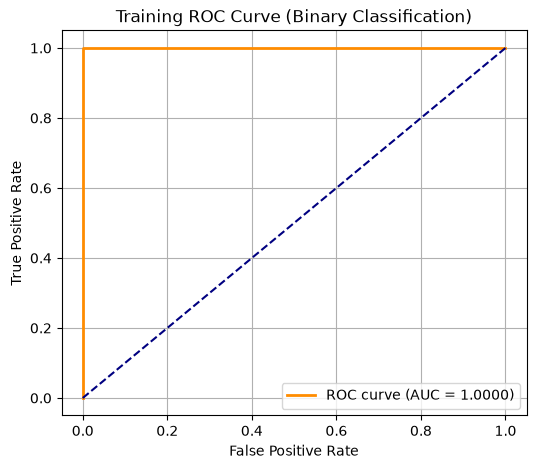

In [16]:
train_opt=fast_split_features(raw_train_cache, l=best_l)
X_train_opt=train_opt.drop(columns=['Activity'])
y_train_opt=train_opt['Activity'].apply(lambda x: 1 if 'bending' in x else 0).values
feature_names_opt=X_train_opt.columns.tolist()

scaler=StandardScaler()
X_train_opt_sc=np.nan_to_num(scaler.fit_transform(X_train_opt), nan=0.0)

base_model=LogisticRegression(penalty=None, solver='lbfgs', max_iter=2000, random_state=42)
rfe_final=RFE(estimator=base_model, n_features_to_select=best_p, step=1)
rfe_final.fit(X_train_opt_sc, y_train_opt)

selected_mask=rfe_final.support_
selected_feature_names=[feature_names_opt[i] for i in range(len(feature_names_opt)) if selected_mask[i]]

X_train_selected=X_train_opt_sc[:, selected_mask]
X_train_sm=sm.add_constant(X_train_selected)

sm_logit=sm.Logit(y_train_opt, X_train_sm)
sm_res=sm_logit.fit(disp=False, maxiter=2000)
print(sm_res.summary(xname=['const']+selected_feature_names))

train_probs=sm_res.predict(X_train_sm)
train_preds=(train_probs>=0.5).astype(int)

print("Train Confusion Matrix:")
print(confusion_matrix(y_train_opt, train_preds))

fpr, tpr, _=roc_curve(y_train_opt, train_probs)
roc_auc=auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Training ROC Curve (Binary Classification)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

#### v. Test Classifier

In [17]:
raw_test_cache=[]
for folder, path in test_files:
    df=pd.read_csv(path, skiprows=4)
    if df.shape[1]==1:
        df=pd.read_csv(path, skiprows=4, sep=r'\s+')
    df=df.iloc[:, 1:7]
    df.columns=columns_of_interest
    df=df.apply(pd.to_numeric, errors='coerce').dropna()
    raw_test_cache.append((folder, df))

test_opt=fast_split_features(raw_test_cache, l=best_l)
X_test_opt=test_opt.drop(columns=['Activity'])
y_test_opt=test_opt['Activity'].apply(lambda x: 1 if 'bending' in x else 0).values

X_test_opt_sc=np.nan_to_num(scaler.transform(X_test_opt), nan=0.0)
X_test_selected=X_test_opt_sc[:, selected_mask]
X_test_sm=sm.add_constant(X_test_selected, has_constant='add')

test_probs=sm_res.predict(X_test_sm)
test_preds=(test_probs>=0.5).astype(int)
test_acc=accuracy_score(y_test_opt, test_preds)

print(f"Optimal CV Accuracy: {best_param['score']:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print("Test Confusion Matrix:")
print(confusion_matrix(y_test_opt, test_preds))

Optimal CV Accuracy: 0.9571
Test Accuracy: 1.0000
Test Confusion Matrix:
[[15  0]
 [ 0  4]]


#### vi. Separation

Training logistic regression without regularization on linearly separable or near-linearly separable classes, maximum likelihood estimates of the parameters diverge toward infinity, causing convergence warnings and degenerate standard errors in Hessian inversion. Restricting max iterations or applying small shrinkage controls parameter explosion.

#### vii. Imbalance

In [18]:
bending_indices=np.where(y_train_opt==1)[0]
non_bending_indices=np.where(y_train_opt==0)[0]

np.random.seed(42)
sampled_non_bending=np.random.choice(non_bending_indices, size=len(bending_indices), replace=False)
balanced_indices=np.concatenate([bending_indices, sampled_non_bending])

X_train_bal=X_train_selected[balanced_indices]
y_train_bal=y_train_opt[balanced_indices]

balanced_model=LogisticRegression(penalty=None, solver='lbfgs', max_iter=2000)
balanced_model.fit(X_train_bal, y_train_bal)

train_bal_preds=balanced_model.predict(X_train_selected)
train_bal_probs=balanced_model.predict_proba(X_train_selected)[:, 1]

print("Balanced Model - Confusion Matrix on Full Train Data:")
print(confusion_matrix(y_train_opt, train_bal_preds))

fpr_bal, tpr_bal, _=roc_curve(y_train_opt, train_bal_probs)
auc_bal=auc(fpr_bal, tpr_bal)
print(f"Balanced Model Training AUC: {auc_bal:.4f}")

Balanced Model - Confusion Matrix on Full Train Data:
[[58  2]
 [ 0  9]]
Balanced Model Training AUC: 1.0000


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [19]:
l1_cv_scores=[]
scaler=StandardScaler()

for l in range(1, 21):
    train_l=extract_split_features(train_files, l=l)
    X_l=train_l.drop(columns=['Activity']).values
    y_l=train_l['Activity'].apply(lambda x: 1 if 'bending' in x else 0).values
    
    X_l_sc=scaler.fit_transform(X_l)
    
    skf=StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    l1_cv=LogisticRegressionCV(
        Cs=np.logspace(-3, 3, 20),
        penalty='l1',
        solver='liblinear',
        cv=skf,
        scoring='accuracy',
        max_iter=2000,
        random_state=42
    )
    l1_cv.fit(X_l_sc, y_l)
    
    best_c=l1_cv.C_[0]
    best_score=np.max(np.mean(l1_cv.scores_[1], axis=0))
    l1_cv_scores.append({'l': l, 'C': best_c, 'best_score': best_score})

l1_results_df=pd.DataFrame(l1_cv_scores)
best_l1=l1_results_df.sort_values(by='best_score', ascending=False).iloc[0]
print(f"Optimal l for L1: {int(best_l1['l'])}, Optimal C: {best_l1['C']:.4f}, CV Score: {best_l1['best_score']:.4f}")

Optimal l for L1: 15, Optimal C: 26.3665, CV Score: 0.9571


#### ii. Comparison

L1 penalized logistic regression directly optimizes variable selection concurrently with parameter estimation via convex optimization, avoiding combinatorial or greedy iterative backward sweeps.

It is significantly faster to implement, scales directly to high-dimensional regimes, and avoids the instability of multi-step RFE refitting.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [21]:
activity_mapping={act: idx for idx, act in enumerate(folders)}
y_train_multi=np.array([activity_mapping[f[0]] for f in train_files])
y_test_multi=np.array([activity_mapping[f[0]] for f in test_files])

multiclass_scores=[]

for l in range(1, 21):
    train_l=fast_split_features(raw_train_cache, l=l)
    X_l=train_l.drop(columns=['Activity']).values
    
    scaler=StandardScaler()
    X_l_sc=np.nan_to_num(scaler.fit_transform(X_l), nan=0.0)
    
    skf=StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    l1_multi_cv=LogisticRegressionCV(
        Cs=np.logspace(-2, 2, 8),
        penalty='l1',
        solver='saga',
        cv=skf,
        scoring='accuracy',
        max_iter=2000,
        random_state=42,
        n_jobs=-1
    )
    l1_multi_cv.fit(X_l_sc, y_train_multi)
    mean_fold_scores=np.mean([np.max(np.mean(l1_multi_cv.scores_[cls], axis=0)) for cls in l1_multi_cv.classes_])
    multiclass_scores.append({'l': l, 'score': mean_fold_scores, 'C': l1_multi_cv.C_[0]})

best_multi=pd.DataFrame(multiclass_scores).sort_values(by='score', ascending=False).iloc[0]
best_multi_l=int(best_multi['l'])
best_multi_C=float(best_multi['C'])
print(f"Best Multi-class l: {best_multi_l}, Optimal C: {best_multi_C:.4f}, Best CV Score: {best_multi['score']:.4f}")

train_multi_opt=fast_split_features(raw_train_cache, l=best_multi_l)
test_multi_opt=fast_split_features(raw_test_cache, l=best_multi_l)

scaler_multi=StandardScaler()
X_tr_m=np.nan_to_num(scaler_multi.fit_transform(train_multi_opt.drop(columns=['Activity']).values), nan=0.0)
X_te_m=np.nan_to_num(scaler_multi.transform(test_multi_opt.drop(columns=['Activity']).values), nan=0.0)

multi_model=LogisticRegression(
    penalty='l1',
    C=best_multi_C,
    solver='saga',
    max_iter=3000,
    random_state=42
)
multi_model.fit(X_tr_m, y_train_multi)

test_multi_preds=multi_model.predict(X_te_m)
print(f"Multinomial Test Error Rate: {1-accuracy_score(y_test_multi, test_multi_preds):.4f}")
print("Test Confusion Matrix (Multiclass):")
print(confusion_matrix(y_test_multi, test_multi_preds))

Best Multi-class l: 2, Optimal C: 1.9307, Best CV Score: 0.9000
Multinomial Test Error Rate: 0.2632
Test Confusion Matrix (Multiclass):
[[2 0 0 0 0 0 0]
 [0 1 0 0 1 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [1 0 0 0 0 2 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]


#### ii. Naive Bayes

In [22]:
gnb=GaussianNB()
gnb.fit(X_tr_m, y_train_multi)
gnb_preds=gnb.predict(X_te_m)
print(f"Gaussian Naive Bayes Test Error Rate: {1-accuracy_score(y_test_multi, gnb_preds):.4f}")

min_max_scaler=MinMaxScaler()
X_tr_m_pos=min_max_scaler.fit_transform(train_multi_opt.drop(columns=['Activity']).values)
X_te_m_pos=min_max_scaler.transform(test_multi_opt.drop(columns=['Activity']).values)

mnb=MultinomialNB()
mnb.fit(X_tr_m_pos, y_train_multi)
mnb_preds=mnb.predict(X_te_m_pos)
print(f"Multinomial Naive Bayes Test Error Rate: {1-accuracy_score(y_test_multi, mnb_preds):.4f}")

Gaussian Naive Bayes Test Error Rate: 0.3158
Multinomial Naive Bayes Test Error Rate: 0.3158


#### ii. Comparison

L1 penalized multinomial regression outperforms Naive Bayes on continuous multi-sensor streams. 
Naive Bayes enforces a strict conditional independence assumption between extracted statistics, degrading its calibration and classification bounds.

## 3. ISLR 4.8.3

$$f_k(x) = \frac{1}{(2\pi)^{p/2} \vert{}\mathbf{\Sigma}\vert{}^{1/2}} \exp\left( -\frac{1}{2} (x - \mu_k)^T \mathbf{\Sigma}^{-1} (x - \mu_k) \right)$$
Applying Bayes' Theorem:$$P(Y = k \mid X = x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}$$
$$\ln(\pi_k f_k(x)) = \ln(\pi_k) + \ln(f_k(x))$$
$$\ln(f_k(x)) = -\frac{p}{2}\ln(2\pi) - \frac{1}{2}\ln\vert{}\mathbf{\Sigma}\vert{} - \frac{1}{2}(x - \mu_k)^T \mathbf{\Sigma}^{-1} (x - \mu_k)$$
$$(x - \mu_k)^T \mathbf{\Sigma}^{-1} (x - \mu_k) = x^T \mathbf{\Sigma}^{-1} x - 2 x^T \mathbf{\Sigma}^{-1} \mu_k + \mu_k^T \mathbf{\Sigma}^{-1} \mu_k$$
$$\ln(\pi_k f_k(x)) = x^T \mathbf{\Sigma}^{-1} \mu_k - \frac{1}{2}\mu_k^T \mathbf{\Sigma}^{-1} \mu_k + \ln(\pi_k) - \frac{1}{2} x^T \mathbf{\Sigma}^{-1} x - \frac{p}{2}\ln(2\pi) - \frac{1}{2}\ln\vert{}\mathbf{\Sigma}\vert{}$$
$$\delta_k(x) = x^T \mathbf{\Sigma}^{-1} \mu_k - \frac{1}{2}\mu_k^T \mathbf{\Sigma}^{-1} \mu_k + \ln(\pi_k)$$
$$x^T \mathbf{\Sigma}^{-1} (\mu_k - \mu_j) - \frac{1}{2}\mu_k^T \mathbf{\Sigma}^{-1} \mu_k + \frac{1}{2}\mu_j^T \mathbf{\Sigma}^{-1} \mu_j + \ln\left(\frac{\pi_k}{\pi_j}\right) = 0$$
This equation describes a linear hyperplane in $\mathbb{R}^p$

## 4. ISLR 4.8.7

$$f(x; \mu, \sigma^2) = \frac{1}{\sqrt{2\pi}\sigma} \exp\left( -\frac{(x - \mu)^2}{2\sigma^2} \right)$$
For $X \mid \text{Yes}$: 
$$\frac{(4 - 10)^2}{2(36)} = \frac{(-6)^2}{72} = \frac{36}{72} = 0.5$$
$$f_{\text{Yes}}(4) = \frac{1}{6\sqrt{2\pi}} e^{-0.5}$$
For $X \mid \text{No}$:
$$\frac{(4 - 0)^2}{2(36)} = \frac{16}{72} = \frac{2}{9} \approx 0.2222$$
$$f_{\text{No}}(4) = \frac{1}{6\sqrt{2\pi}} e^{-2/9}$$
Applying Bayes' Theorem:$$P(\text{Yes} \mid X = 4) = \frac{\pi_{\text{Yes}} f_{\text{Yes}}(4)}{\pi_{\text{Yes}} f_{\text{Yes}}(4) + \pi_{\text{No}} f_{\text{No}}(4)}$$
$$P(\text{Yes} \mid X = 4) = \frac{0.80 \cdot e^{-0.5}}{0.80 \cdot e^{-0.5} + 0.20 \cdot e^{-2/9}}$$
$$P(\text{Yes} \mid X = 4) =  0.75185$$

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9